# Lab Sheet-II

Systems + Milne PC. Methods take `f` as argument (work for any system size).

## Q1. RK4 for a system of two equations

$y_1'=-2y_1+y_2$, $y_2'=y_1-2y_2$, $y_1(0)=2$, $y_2(0)=0$, $0\le x\le 1$  
exact: $y_1=e^{-x}+e^{-3x}$, $y_2=e^{-x}-e^{-3x}$  
$h=0.1$ and $h=0.05$

--- h = 0.1 ---
       x        y1 num        y2 num        y1 err        y2 err
    0.00      2.000000      0.000000  0.000000e+00  0.000000e+00
    0.10      1.645675      0.164000  1.936128e-05  1.919735e-05
    0.20      1.367571      0.269891  2.871364e-05  2.841698e-05
    0.30      1.147420      0.334217  3.194429e-05  3.154165e-05
    0.40      0.971546      0.369095  3.159765e-05  3.111189e-05
    0.50      0.829690      0.383372  2.931032e-05  2.876090e-05
    0.60      0.714137      0.383487  2.611075e-05  2.551418e-05
    0.70      0.619064      0.374107  2.262457e-05  2.199481e-05
    0.80      0.540066      0.358592  1.921435e-05  1.856311e-05
    0.90      0.473791      0.339349  1.607392e-05  1.541100e-05
    1.00      0.417680      0.318080  1.329152e-05  1.262504e-05



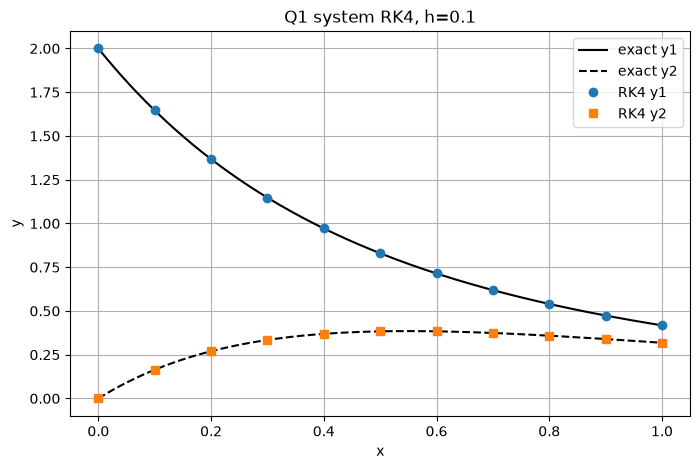

--- h = 0.05 ---
       x        y1 num        y2 num        y1 err        y2 err
    0.00      2.000000      0.000000  0.000000e+00  0.000000e+00
    0.05      1.811938      0.090521  6.199076e-07  6.147423e-07
    0.10      1.645657      0.164018  1.067587e-06  1.057760e-06
    0.15      1.498338      0.223078  1.378988e-06  1.364967e-06
    0.20      1.367544      0.269918  1.583388e-06  1.565605e-06
    0.25      1.251169      0.306433  1.704550e-06  1.683406e-06
    0.30      1.147390      0.334247  1.761693e-06  1.737557e-06
    0.35      1.054628      0.354749  1.770296e-06  1.743510e-06
    0.40      0.971516      0.369124  1.742766e-06  1.713647e-06
    0.45      0.896870      0.378386  1.688998e-06  1.657836e-06
    0.50      0.829662      0.383399  1.616827e-06  1.583892e-06
    0.55      0.769001      0.384898  1.532418e-06  1.497957e-06
    0.60      0.714112      0.383511  1.440572e-06  1.404811e-06
    0.65      0.664321      0.379770  1.344992e-06  1.308141e-06
    0.70

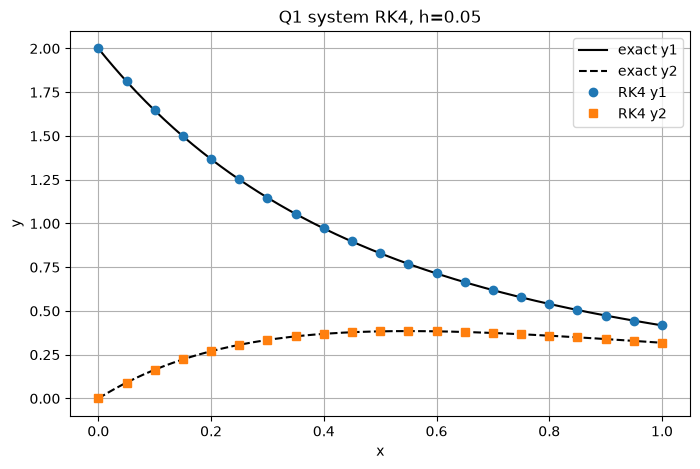

at x=1, err ratio y1: 18.10, y2: 18.19
close to 16 => order 4 (halving h cuts error by ~16)


In [1]:
import numpy as np
import matplotlib.pyplot as plt


def rk4(f, x0, y0, h, x_end):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[0] = y0

    for i in range(n):
        k1 = f(x[i], Y[i])
        k2 = f(x[i] + h/2, Y[i] + h*k1/2)
        k3 = f(x[i] + h/2, Y[i] + h*k2/2)
        k4 = f(x[i] + h, Y[i] + h*k3)
        Y[i + 1] = Y[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

    return x, Y


def f1(x, y):
    y1, y2 = y
    return np.array([-2*y1 + y2, y1 - 2*y2])


def exact1(x):
    y1 = np.exp(-x) + np.exp(-3*x)
    y2 = np.exp(-x) - np.exp(-3*x)
    return y1, y2


errors_at_1 = {}

for h in [0.1, 0.05]:
    x, Y = rk4(f1, 0.0, np.array([2.0, 0.0]), h, 1.0)
    y1e, y2e = exact1(x)
    e1 = np.abs(Y[:, 0] - y1e)
    e2 = np.abs(Y[:, 1] - y2e)

    print(f"--- h = {h} ---")
    print(f"{'x':>8}  {'y1 num':>12}  {'y2 num':>12}  {'y1 err':>12}  {'y2 err':>12}")
    for i in range(len(x)):
        print(f"{x[i]:8.2f}  {Y[i,0]:12.6f}  {Y[i,1]:12.6f}  {e1[i]:12.6e}  {e2[i]:12.6e}")
    print()

    errors_at_1[h] = (e1[-1], e2[-1])

    xx = np.linspace(0, 1, 300)
    ye1, ye2 = exact1(xx)
    plt.figure(figsize=(8, 5))
    plt.plot(xx, ye1, "k-", label="exact y1")
    plt.plot(xx, ye2, "k--", label="exact y2")
    plt.plot(x, Y[:, 0], "o", label="RK4 y1")
    plt.plot(x, Y[:, 1], "s", label="RK4 y2")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Q1 system RK4, h={h}")
    plt.legend()
    plt.grid()
    plt.show()

# order check at x=1
r1 = errors_at_1[0.1][0] / errors_at_1[0.05][0]
r2 = errors_at_1[0.1][1] / errors_at_1[0.05][1]
print(f"at x=1, err ratio y1: {r1:.2f}, y2: {r2:.2f}")
print("close to 16 => order 4 (halving h cuts error by ~16)")

## Q2. Higher-order IVP

$y''+2y'+5y=0$, $y(0)=1$, $y'(0)=0$, $0\le x\le 2$  
as system: $u_1=y$, $u_2=y'$ → $u_1'=u_2$, $u_2'=-5u_1-2u_2$  
exact: $y=e^{-x}(\cos 2x + \frac12\sin 2x)$  
$h=0.1$ and $h=0.4$

--- h = 0.1 ---
       x         y num       y exact       |error|        y' num
    0.00      1.000000      1.000000  0.000000e+00      0.000000
    0.10      0.976688      0.976683  4.866043e-06     -0.449417
    0.20      0.913523      0.913515  8.057020e-06     -0.797089
    0.30      0.820582      0.820572  9.482968e-06     -1.045770
    0.40      0.707455      0.707446  9.232273e-06     -1.202179
    0.50      0.582906      0.582899  7.527956e-06     -1.275983
    0.60      0.454628      0.454623  4.683779e-06     -1.278825
    0.70      0.329084      0.329083  1.062950e-06     -1.223440
    0.80      0.211446      0.211448  2.958452e-06     -1.122881
    0.90      0.105588      0.105595  7.021939e-06     -0.989874
    1.00      0.014153      0.014164  1.081021e-05     -0.836304
    1.10     -0.061347     -0.061332  1.406366e-05     -0.672829
    1.20     -0.120393     -0.120376  1.659014e-05     -0.508621
    1.30     -0.163302     -0.163284  1.826846e-05     -0.351225
    1.40 

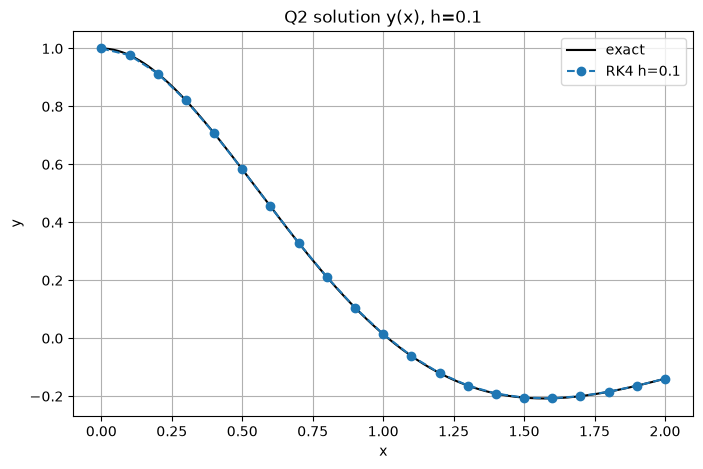

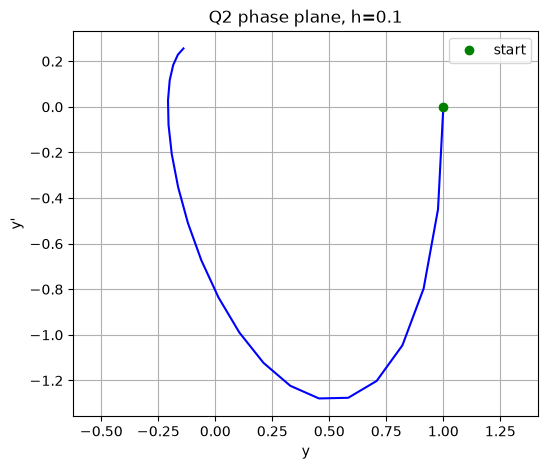

--- h = 0.4 ---
       x         y num       y exact       |error|        y' num
    0.00      1.000000      1.000000  0.000000e+00      0.000000
    0.40      0.712000      0.707446  4.554443e-03     -1.210667
    0.80      0.213801      0.211448  2.352750e-03     -1.137704
    1.20     -0.123250     -0.120376  2.873614e-03     -0.517935
    1.60     -0.213163     -0.207445  5.718018e-03      0.031263
    2.00     -0.144202     -0.139672  4.530173e-03      0.265189
max |error| = 5.718018e-03



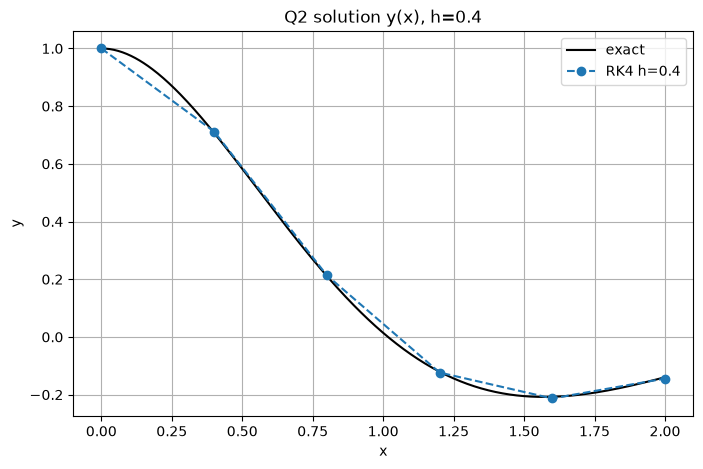

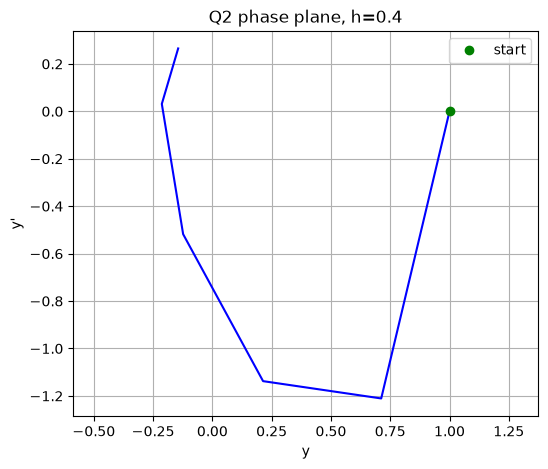

phase plane: spiral into origin (damped oscillation)
with h=0.4: fewer points, larger error, but still captures the decay/spiral


In [2]:
import numpy as np
import matplotlib.pyplot as plt


def rk4(f, x0, y0, h, x_end):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[0] = y0

    for i in range(n):
        k1 = f(x[i], Y[i])
        k2 = f(x[i] + h/2, Y[i] + h*k1/2)
        k3 = f(x[i] + h/2, Y[i] + h*k2/2)
        k4 = f(x[i] + h, Y[i] + h*k3)
        Y[i + 1] = Y[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

    return x, Y


def f2(x, u):
    # u = [y, y']
    return np.array([u[1], -5*u[0] - 2*u[1]])


def exact2(x):
    return np.exp(-x)*(np.cos(2*x) + 0.5*np.sin(2*x))


for h in [0.1, 0.4]:
    x, U = rk4(f2, 0.0, np.array([1.0, 0.0]), h, 2.0)
    y_ex = exact2(x)
    err = np.abs(U[:, 0] - y_ex)

    print(f"--- h = {h} ---")
    print(f"{'x':>8}  {'y num':>12}  {'y exact':>12}  {'|error|':>12}  {'y\' num':>12}")
    for i in range(len(x)):
        print(f"{x[i]:8.2f}  {U[i,0]:12.6f}  {y_ex[i]:12.6f}  {err[i]:12.6e}  {U[i,1]:12.6f}")
    print(f"max |error| = {err.max():.6e}\n")

    # y vs x
    xx = np.linspace(0, 2, 400)
    plt.figure(figsize=(8, 5))
    plt.plot(xx, exact2(xx), "k-", label="exact")
    plt.plot(x, U[:, 0], "o--", label=f"RK4 h={h}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Q2 solution y(x), h={h}")
    plt.legend()
    plt.grid()
    plt.show()

    # phase plane (y, y')
    plt.figure(figsize=(6, 5))
    plt.plot(U[:, 0], U[:, 1], "b-")
    plt.plot(U[0, 0], U[0, 1], "go", label="start")
    plt.xlabel("y")
    plt.ylabel("y'")
    plt.title(f"Q2 phase plane, h={h}")
    plt.legend()
    plt.grid()
    plt.axis("equal")
    plt.show()

# RK4 amplification factor R(z) = 1 + z + z^2/2 + z^3/6 + z^4/24, z = h*lambda
lam = -1 + 2j   # eigenvalue of the system (roots of r^2 + 2r + 5 = 0)
for h in [0.1, 0.4]:
    z = h*lam
    R = 1 + z + z**2/2 + z**3/6 + z**4/24
    print(f"h={h}: |R(h*lambda)| = {abs(R):.4f},  exact |e^(h*lambda)| = {abs(np.exp(z)):.4f}")

print("\nphase plane: spiral into origin (damped oscillation)")
print("h=0.4: only 6 points, error ~300x larger, but |R| < 1 so RK4 is still stable")
print("and the solution still spirals in; it decays slightly slower than the exact one")

## Q3. Predator–prey (Lotka–Volterra)

$y_1'=1.5 y_1 - y_1 y_2$, $y_2'=-3 y_2 + y_1 y_2$  
$y_1(0)=10$, $y_2(0)=5$, $0\le x\le 15$, $h=0.05$  
$V=d y_1 - c\ln y_1 + b y_2 - a\ln y_2$ should be constant along exact solution  
RK4 and Heun

V(y1(0), y2(0)) = 5.6780878524

RK4: max |V - V0| = 8.624608e-04
Heun: max |V - V0| = 4.084095e-01


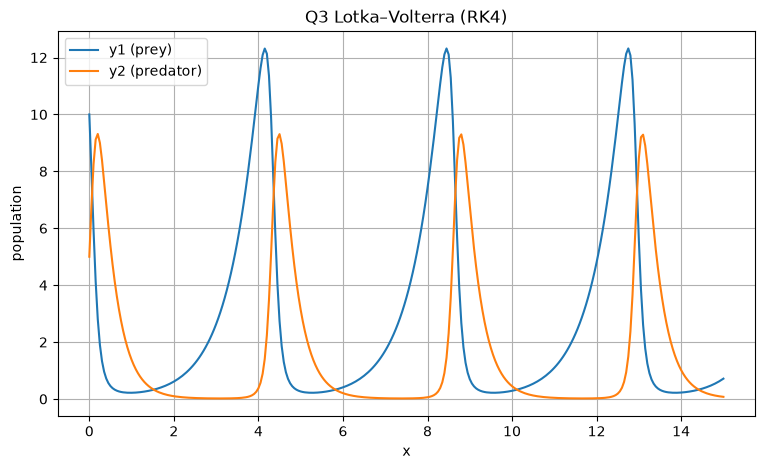

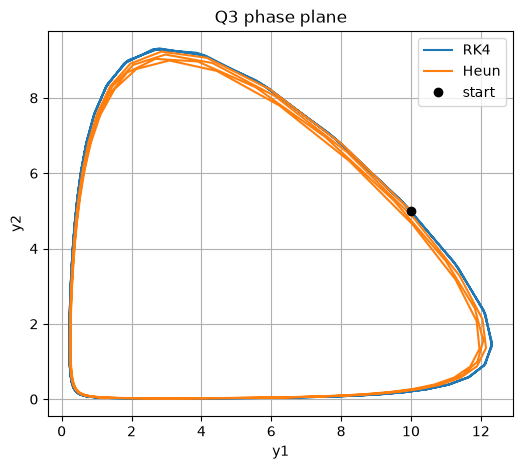

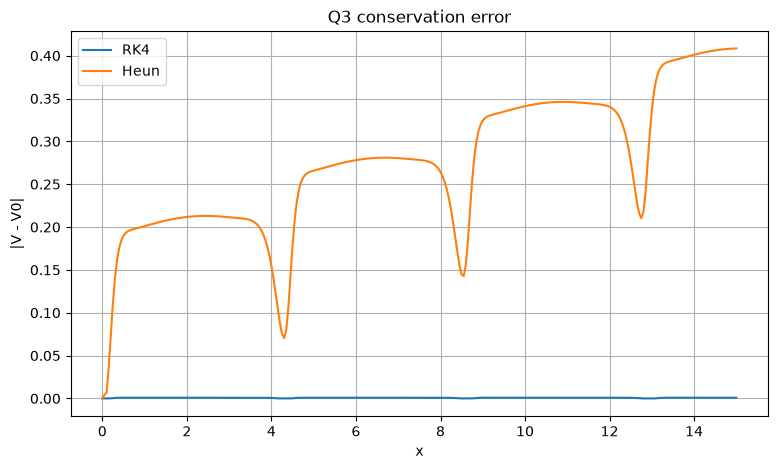

V should stay constant; |V-V0| shows numerical drift.
RK4 keeps V much better than Heun (same h).


In [3]:
import numpy as np
import matplotlib.pyplot as plt


def rk4(f, x0, y0, h, x_end):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[0] = y0

    for i in range(n):
        k1 = f(x[i], Y[i])
        k2 = f(x[i] + h/2, Y[i] + h*k1/2)
        k3 = f(x[i] + h/2, Y[i] + h*k2/2)
        k4 = f(x[i] + h, Y[i] + h*k3)
        Y[i + 1] = Y[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

    return x, Y


def heun(f, x0, y0, h, x_end):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[0] = y0

    for i in range(n):
        k1 = f(x[i], Y[i])
        y_predict = Y[i] + h*k1
        k2 = f(x[i + 1], y_predict)
        Y[i + 1] = Y[i] + (h/2)*(k1 + k2)

    return x, Y


a, b, c, d = 1.5, 1.0, 3.0, 1.0


def f3(x, y):
    y1, y2 = y
    return np.array([a*y1 - b*y1*y2, -c*y2 + d*y1*y2])


def V(y1, y2):
    return d*y1 - c*np.log(y1) + b*y2 - a*np.log(y2)


# check dV/dx = 0 analytically along exact flow:
# dV/dx = (d - c/y1)*y1' + (b - a/y2)*y2'
#       = (d - c/y1)(a y1 - b y1 y2) + (b - a/y2)(-c y2 + d y1 y2)
# which cancels to 0 (conserved quantity)

h = 0.05
y0 = np.array([10.0, 5.0])
V0 = V(10.0, 5.0)
print(f"V(y1(0), y2(0)) = {V0:.10f}\n")

results = {}
for name, solver in [("RK4", rk4), ("Heun", heun)]:
    x, Y = solver(f3, 0.0, y0, h, 15.0)
    Vn = V(Y[:, 0], Y[:, 1])
    dV = np.abs(Vn - V0)
    results[name] = (x, Y, dV)

    print(f"{name}: max |V - V0| = {dV.max():.6e}")
    for xi in [5, 10, 15]:
        i = int(round(xi/h))
        print(f"    |V - V0| at x={xi}: {dV[i]:.6e}")

# time series RK4
x, Y, dV = results["RK4"]
plt.figure(figsize=(9, 5))
plt.plot(x, Y[:, 0], label="y1 (prey)")
plt.plot(x, Y[:, 1], label="y2 (predator)")
plt.xlabel("x")
plt.ylabel("population")
plt.title("Q3 Lotka–Volterra (RK4)")
plt.legend()
plt.grid()
plt.show()

# phase plane both methods
plt.figure(figsize=(6, 5))
for name in ["RK4", "Heun"]:
    x, Y, dV = results[name]
    plt.plot(Y[:, 0], Y[:, 1], label=name)
plt.plot(10, 5, "ko", label="start")
plt.xlabel("y1")
plt.ylabel("y2")
plt.title("Q3 phase plane")
plt.legend()
plt.grid()
plt.show()

# |V-V0| vs x
plt.figure(figsize=(9, 5))
for name in ["RK4", "Heun"]:
    x, Y, dV = results[name]
    plt.plot(x, dV, label=name)
plt.xlabel("x")
plt.ylabel("|V - V0|")
plt.title("Q3 conservation error")
plt.legend()
plt.grid()
plt.show()

print("V should stay constant; |V-V0| shows numerical drift.")
print("RK4: drift ~1e-3, almost all of it in the first cycle, then nearly flat (8.2e-4 -> 8.4e-4).")
print("Heun: drift ~0.4 and keeps growing every cycle, so its orbit slowly shrinks inward (V decreases).")
print("RK4 is far more accurate than Heun for the same h.")

## Q4. Milne’s predictor–corrector

(a) $y'=1+y^2$, $y(0)=0$, exact $y=\tan x$, $h=0.1$  
(b) $y'=x+y$, $y(0)=1$, exact $y=2e^x-x-1$, compare with Heun

=== (a) y' = 1 + y^2 ===
     x        y_pred        y_corr   iters     Milne est    actual err
  0.00     RK4 start      0.000000       0           ---  0.000000e+00
  0.10     RK4 start      0.100335       0           ---  8.300729e-08
  0.20     RK4 start      0.202710       0           ---  1.572770e-07
  0.30     RK4 start      0.309336       0           ---  2.102646e-07
  0.40      0.422723      0.422797       5  -2.549951e-06  3.441204e-06
  0.50      0.546202      0.546308       6  -3.657287e-06  5.871970e-06
  0.60      0.683980      0.684151       6  -5.896055e-06  1.421644e-05
  0.70      0.842028      0.842315       7  -9.909960e-06  2.657499e-05
  0.80      1.029174      1.029695       7  -1.794805e-05  5.619591e-05
  0.90      1.259265      1.260278       8  -3.492381e-05  1.193793e-04
  1.00      1.555527      1.557690       9  -7.461294e-05  2.826657e-04


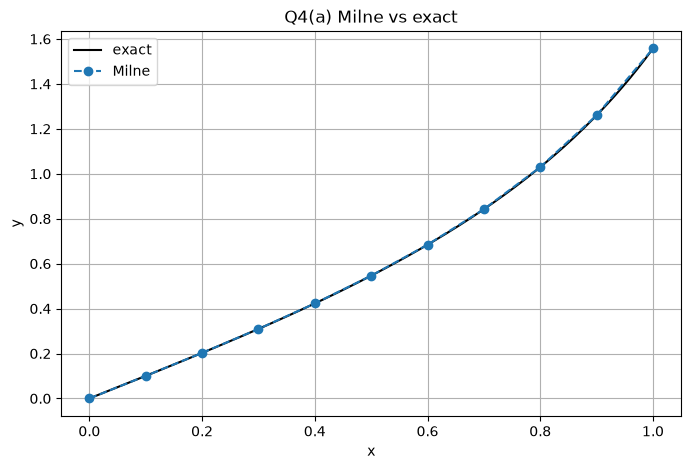

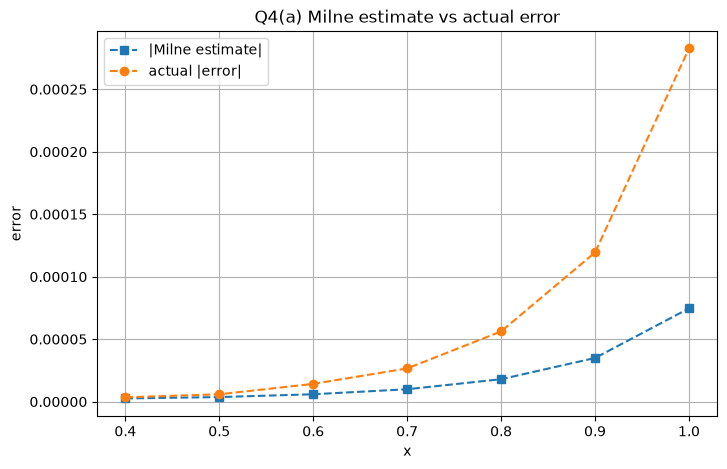

estimate tracks the size of true error reasonably (same order)

=== (b) y' = x + y ===
     x         Milne          Heun         Exact     Milne err      Heun err
  0.00      1.000000      1.000000      1.000000  0.000000e+00  0.000000e+00
  0.10      1.110342      1.110000      1.110342  1.694846e-07  3.418362e-04
  0.20      1.242805      1.242050      1.242806  3.746190e-07  7.555163e-04
  0.30      1.399717      1.398465      1.399718  6.210269e-07  1.252365e-03
  0.40      1.583649      1.581804      1.583649  1.756538e-07  1.845294e-03
  0.50      1.797442      1.794894      1.797443  3.449733e-07  2.549010e-03
  0.60      2.044238      2.040857      2.044238  1.438461e-07  3.380248e-03
  0.70      2.327505      2.323147      2.327505  7.015326e-08  4.358040e-03
  0.80      2.651082      2.645578      2.651082  6.265945e-07  5.504008e-03
  0.90      3.019207      3.012364      3.019206  6.732800e-07  6.842699e-03
  1.00      3.436565      3.428162      3.436564  1.328369e-06  8.

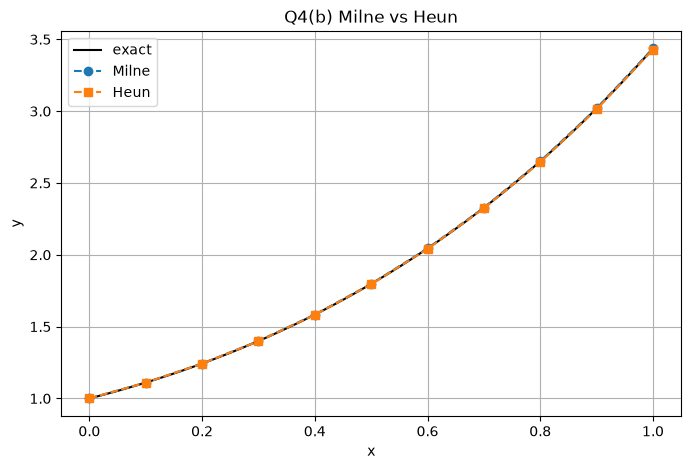

In [4]:
import numpy as np
import matplotlib.pyplot as plt


def rk4(f, x0, y0, h, x_end):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[0] = y0

    for i in range(n):
        k1 = f(x[i], Y[i])
        k2 = f(x[i] + h/2, Y[i] + h*k1/2)
        k3 = f(x[i] + h/2, Y[i] + h*k2/2)
        k4 = f(x[i] + h, Y[i] + h*k3)
        Y[i + 1] = Y[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

    return x, Y


def heun(f, x0, y0, h, x_end):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[0] = y0

    for i in range(n):
        k1 = f(x[i], Y[i])
        y_predict = Y[i] + h*k1
        k2 = f(x[i + 1], y_predict)
        Y[i + 1] = Y[i] + (h/2)*(k1 + k2)

    return x, Y


def milne(f, x0, y0, h, x_end, tol=1e-10):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)

    # y0, y1, y2, y3 from RK4
    _, start = rk4(f, x0, y0, h, x0 + 3*h)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[:4] = start

    F = np.zeros_like(Y)
    for i in range(4):
        F[i] = f(x[i], Y[i])

    predicted = np.full_like(Y, np.nan)
    estimate = np.full_like(Y, np.nan)
    iterations = np.zeros(n + 1, dtype=int)

    for i in range(3, n):
        y_predict = Y[i - 3] + (4*h/3)*(2*F[i - 2] - F[i - 1] + 2*F[i])
        predicted[i + 1] = y_predict

        y_old = y_predict.copy()
        for count in range(1, 101):
            y_new = Y[i - 1] + (h/3)*(F[i - 1] + 4*F[i] + f(x[i + 1], y_old))
            if np.max(np.abs(y_new - y_old)) < tol:
                break
            y_old = y_new

        Y[i + 1] = y_new
        F[i + 1] = f(x[i + 1], Y[i + 1])
        iterations[i + 1] = count
        estimate[i + 1] = -(Y[i + 1] - y_predict)/29

    return x, Y, predicted, iterations, estimate


# ---- (a) y' = 1 + y^2 ----
def fa(x, y):
    return 1 + y**2


h = 0.1
x, Y, preds, iters, est = milne(fa, 0.0, 0.0, h, 1.0)
exact = np.tan(x)
signed_err = exact - Y          # y(x_n) - y_n, same sign convention as Milne's estimate
actual_err = np.abs(signed_err)

print("=== (a) y' = 1 + y^2 ===")
print(f"{'x':>6}  {'y_pred':>12}  {'y_corr':>12}  {'iters':>6}  {'Milne est':>13}  {'actual err':>13}")
for i in range(len(x)):
    p = preds[i]
    e = est[i]
    p_s = f"{p:12.6f}" if np.isfinite(p) else f"{'RK4 start':>12}"
    e_s = f"{e:+13.6e}" if np.isfinite(e) else f"{'---':>13}"
    print(f"{x[i]:6.2f}  {p_s}  {Y[i]:12.6f}  {iters[i]:6d}  {e_s}  {signed_err[i]:+13.6e}")

xx = np.linspace(0, 1, 300)
plt.figure(figsize=(8, 5))
plt.plot(xx, np.tan(xx), "k-", label="exact")
plt.plot(x, Y, "o--", label="Milne")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q4(a) Milne vs exact")
plt.legend()
plt.grid()
plt.show()

# milne estimate vs actual error (from where milne starts)
mask = np.isfinite(est)
plt.figure(figsize=(8, 5))
plt.plot(x[mask], np.abs(est[mask]), "s--", label="|Milne estimate|")
plt.plot(x[mask], actual_err[mask], "o--", label="actual |error|")
plt.xlabel("x")
plt.ylabel("error")
plt.title("Q4(a) Milne estimate vs actual error")
plt.legend()
plt.grid()
plt.show()

print("estimate has the correct sign and order of magnitude,")
print("but it underestimates: actual/estimate grows from ~1.3 at x=0.4 to ~3.8 at x=1.")
print("Reason: the estimate measures only the local error of one step,")
print("while the actual error is accumulated over all steps (and tan x grows fast).")

# ---- (b) y' = x + y, compare with Heun ----
def fb(x, y):
    return x + y


x_m, Y_m, _, _, _ = milne(fb, 0.0, 1.0, h, 1.0)
x_h, Y_h = heun(fb, 0.0, 1.0, h, 1.0)
exact_b = 2*np.exp(x_m) - x_m - 1

print("\n=== (b) y' = x + y ===")
print(f"{'x':>6}  {'Milne':>12}  {'Heun':>12}  {'Exact':>12}  {'Milne err':>12}  {'Heun err':>12}")
for i in range(len(x_m)):
    em = abs(Y_m[i] - exact_b[i])
    eh = abs(Y_h[i] - exact_b[i])
    print(f"{x_m[i]:6.2f}  {Y_m[i]:12.6f}  {Y_h[i]:12.6f}  {exact_b[i]:12.6f}  {em:12.6e}  {eh:12.6e}")

print(f"\nat x=1: Milne err={abs(Y_m[-1]-exact_b[-1]):.6e}, Heun err={abs(Y_h[-1]-exact_b[-1]):.6e}")
print("Milne (multistep order 4) is much more accurate than Heun (order 2)")

plt.figure(figsize=(8, 5))
plt.plot(xx, 2*np.exp(xx)-xx-1, "k-", label="exact")
plt.plot(x_m, Y_m, "o--", label="Milne")
plt.plot(x_h, Y_h, "s--", label="Heun")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q4(b) Milne vs Heun")
plt.legend()
plt.grid()
plt.show()

## Q5(a). Comparative study — logistic

$y'=y(1-y)$, $y(0)=0.5$, RK4 and Milne, $h=0.25$ and $0.125$

=== h = 0.25 ===
       x           RK4         Milne         Exact       RK4 err     Milne err
   0.000      0.500000      0.500000      0.500000  0.000000e+00  0.000000e+00
   0.250      0.562176      0.562176      0.562177  1.279719e-07  1.279719e-07
   0.500      0.622459      0.622459      0.622459  2.775424e-07  2.775424e-07
   0.750      0.679178      0.679178      0.679179  4.716924e-07  4.716924e-07
   1.000      0.731058      0.731059      0.731059  7.180226e-07  1.657021e-07



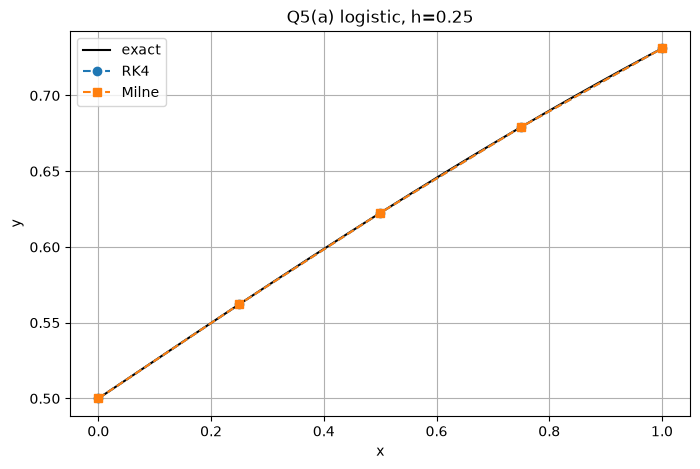

=== h = 0.125 ===
       x           RK4         Milne         Exact       RK4 err     Milne err
   0.000      0.500000      0.500000      0.500000  0.000000e+00  0.000000e+00
   0.125      0.531209      0.531209      0.531209  3.979879e-09  3.979879e-09
   0.250      0.562176      0.562176      0.562177  8.126252e-09  8.126252e-09
   0.375      0.592667      0.592667      0.592667  1.264810e-08  1.264810e-08
   0.500      0.622459      0.622459      0.622459  1.772391e-08  5.311307e-08
   0.625      0.651355      0.651355      0.651355  2.348211e-08  3.080598e-08
   0.750      0.679179      0.679179      0.679179  2.998613e-08  7.877250e-08
   0.875      0.705785      0.705785      0.705785  3.722633e-08  3.700319e-08
   1.000      0.731059      0.731059      0.731059  4.511940e-08  6.993497e-08



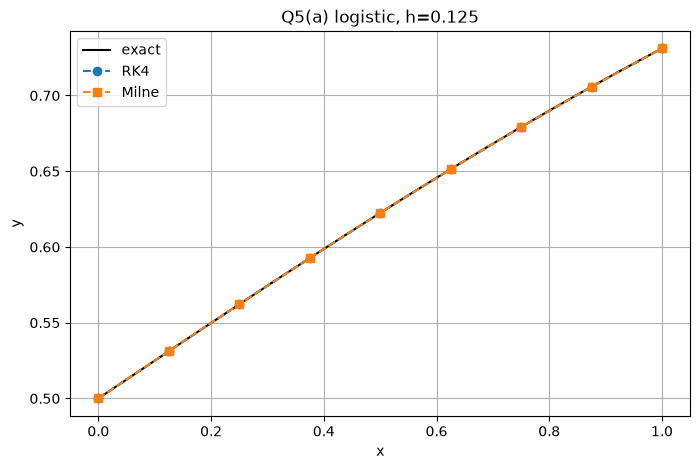

both are accurate; compare with Lab-I table (Euler/Heun/mid/RK4/bwd)
RK4 and Milne beat the lower-order methods from Lab Sheet-I


In [5]:
import numpy as np
import matplotlib.pyplot as plt


def rk4(f, x0, y0, h, x_end):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[0] = y0

    for i in range(n):
        k1 = f(x[i], Y[i])
        k2 = f(x[i] + h/2, Y[i] + h*k1/2)
        k3 = f(x[i] + h/2, Y[i] + h*k2/2)
        k4 = f(x[i] + h, Y[i] + h*k3)
        Y[i + 1] = Y[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

    return x, Y


def milne(f, x0, y0, h, x_end, tol=1e-10):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)

    _, start = rk4(f, x0, y0, h, x0 + 3*h)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[:4] = start

    F = np.zeros_like(Y)
    for i in range(4):
        F[i] = f(x[i], Y[i])

    predicted = np.full_like(Y, np.nan)
    estimate = np.full_like(Y, np.nan)
    iterations = np.zeros(n + 1, dtype=int)

    for i in range(3, n):
        y_predict = Y[i - 3] + (4*h/3)*(2*F[i - 2] - F[i - 1] + 2*F[i])
        predicted[i + 1] = y_predict

        y_old = y_predict.copy()
        for count in range(1, 101):
            y_new = Y[i - 1] + (h/3)*(F[i - 1] + 4*F[i] + f(x[i + 1], y_old))
            if np.max(np.abs(y_new - y_old)) < tol:
                break
            y_old = y_new

        Y[i + 1] = y_new
        F[i + 1] = f(x[i + 1], Y[i + 1])
        iterations[i + 1] = count
        estimate[i + 1] = -(Y[i + 1] - y_predict)/29

    return x, Y, predicted, iterations, estimate


# Lab Sheet-I methods, for comparison
def euler(f, x0, y0, h, x_end):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[0] = y0
    for i in range(n):
        Y[i + 1] = Y[i] + h*f(x[i], Y[i])
    return x, Y


def backward_euler(f, x0, y0, h, x_end, tol=1e-12):
    # solve y = y_n + h f(x_{n+1}, y) by fixed-point iteration
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[0] = y0
    for i in range(n):
        y_old = Y[i] + h*f(x[i], Y[i])
        for _ in range(200):
            y_new = Y[i] + h*f(x[i + 1], y_old)
            if np.max(np.abs(y_new - y_old)) < tol:
                break
            y_old = y_new
        Y[i + 1] = y_new
    return x, Y


def heun(f, x0, y0, h, x_end):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[0] = y0
    for i in range(n):
        k1 = f(x[i], Y[i])
        k2 = f(x[i + 1], Y[i] + h*k1)
        Y[i + 1] = Y[i] + (h/2)*(k1 + k2)
    return x, Y


def midpoint(f, x0, y0, h, x_end):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[0] = y0
    for i in range(n):
        k1 = f(x[i], Y[i])
        Y[i + 1] = Y[i] + h*f(x[i] + h/2, Y[i] + h*k1/2)
    return x, Y


def f5a(x, y):
    return y*(1 - y)


def exact5a(x):
    return 1/(1 + np.exp(-x))


for h in [0.25, 0.125]:
    x_r, Y_r = rk4(f5a, 0.0, 0.5, h, 1.0)
    x_m, Y_m, _, _, _ = milne(f5a, 0.0, 0.5, h, 1.0)
    ex = exact5a(x_r)

    print(f"=== h = {h} ===")
    print(f"{'x':>8}  {'RK4':>12}  {'Milne':>12}  {'Exact':>12}  {'RK4 err':>12}  {'Milne err':>12}")
    for i in range(len(x_r)):
        print(f"{x_r[i]:8.3f}  {Y_r[i]:12.6f}  {Y_m[i]:12.6f}  {ex[i]:12.6f}  "
              f"{abs(Y_r[i]-ex[i]):12.6e}  {abs(Y_m[i]-ex[i]):12.6e}")
    print()

    xx = np.linspace(0, 1, 200)
    plt.figure(figsize=(8, 5))
    plt.plot(xx, exact5a(xx), "k-", label="exact")
    plt.plot(x_r, Y_r, "o--", label="RK4")
    plt.plot(x_m, Y_m, "s--", label="Milne")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Q5(a) logistic, h={h}")
    plt.legend()
    plt.grid()
    plt.show()

# comparison with all methods of Lab Sheet-I, at x = 1
methods = [("Euler", euler), ("Backward Euler", backward_euler), ("Heun", heun),
           ("Midpoint", midpoint), ("RK4", rk4)]

for h in [0.25, 0.125]:
    print(f"=== all methods at x=1, h = {h} ===")
    print(f"{'method':>16}  {'y(1)':>12}  {'|error|':>12}")
    for name, solver in methods:
        x, Y = solver(f5a, 0.0, 0.5, h, 1.0)
        print(f"{name:>16}  {Y[-1]:12.6f}  {abs(Y[-1] - exact5a(1.0)):12.6e}")
    x, Y, _, _, _ = milne(f5a, 0.0, 0.5, h, 1.0)
    print(f"{'Milne':>16}  {Y[-1]:12.6f}  {abs(Y[-1] - exact5a(1.0)):12.6e}")
    print()

print("RK4 and Milne (both order 4) have errors below 1e-6, far smaller than")
print("Heun / midpoint (order 2, ~1e-5 to 1e-3) and Euler / backward Euler (order 1, ~3e-3 to 6e-3).")
print("Halving h: Euler errors halve, Heun/midpoint drop ~4x, RK4 drops ~16x.")

## Q5(b). Long interval — $y'=-y$

$y(0)=1$, $0\le x\le 20$, exact $e^{-x}$  
RK4 and Milne with $h=0.1$; then Milne with $h=0.05$, $0.025$

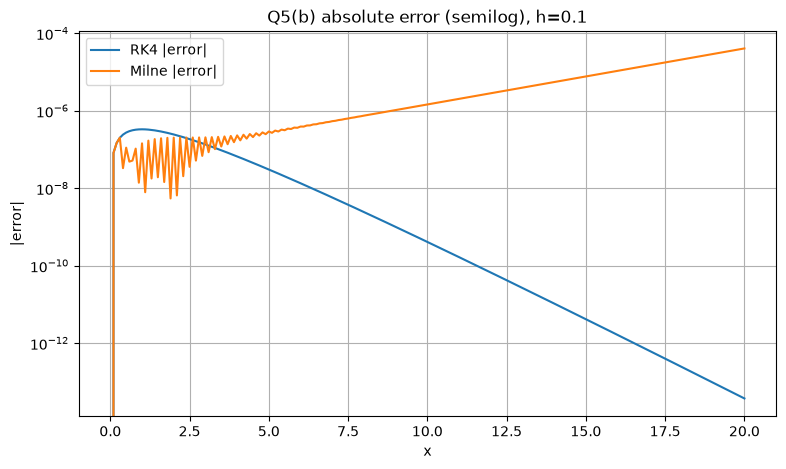

at x=20: RK4 err=3.734196e-14, Milne err=4.083245e-05
Milne h=0.1: max err=4.083245e-05, err at x=20=4.083245e-05
Milne h=0.05: max err=1.481173e-06, err at x=20=1.481173e-06
Milne h=0.025: max err=4.647929e-08, err at x=20=4.647929e-08


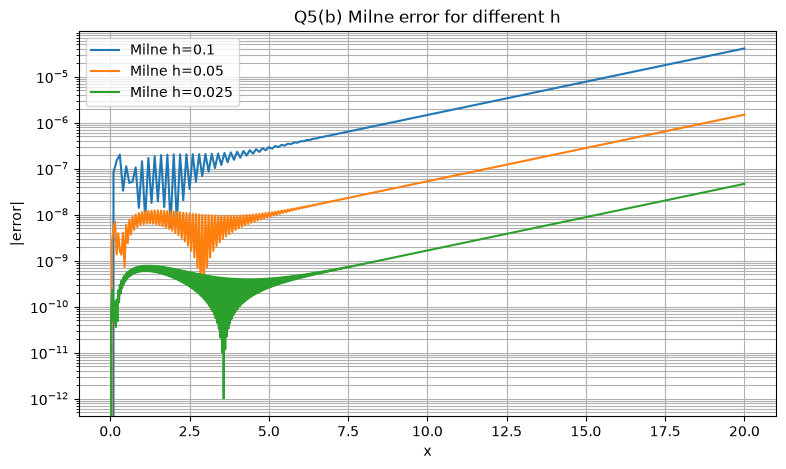


Milne has a weak stability / parasitic root issue.
On long intervals the error can grow even if local truncation is small.
Reducing h often only postpones the blow-up, does not remove it.
Prefer RK4 (or a strongly stable multistep method) for long integrations.


In [6]:
import numpy as np
import matplotlib.pyplot as plt


def rk4(f, x0, y0, h, x_end):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[0] = y0

    for i in range(n):
        k1 = f(x[i], Y[i])
        k2 = f(x[i] + h/2, Y[i] + h*k1/2)
        k3 = f(x[i] + h/2, Y[i] + h*k2/2)
        k4 = f(x[i] + h, Y[i] + h*k3)
        Y[i + 1] = Y[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

    return x, Y


def milne(f, x0, y0, h, x_end, tol=1e-10):
    y0 = np.asarray(y0, dtype=float)
    n = int(round((x_end - x0)/h))
    x = np.linspace(x0, x_end, n + 1)

    _, start = rk4(f, x0, y0, h, x0 + 3*h)
    Y = np.zeros((n + 1,) + y0.shape)
    Y[:4] = start

    F = np.zeros_like(Y)
    for i in range(4):
        F[i] = f(x[i], Y[i])

    predicted = np.full_like(Y, np.nan)
    estimate = np.full_like(Y, np.nan)
    iterations = np.zeros(n + 1, dtype=int)

    for i in range(3, n):
        y_predict = Y[i - 3] + (4*h/3)*(2*F[i - 2] - F[i - 1] + 2*F[i])
        predicted[i + 1] = y_predict

        y_old = y_predict.copy()
        for count in range(1, 101):
            y_new = Y[i - 1] + (h/3)*(F[i - 1] + 4*F[i] + f(x[i + 1], y_old))
            if np.max(np.abs(y_new - y_old)) < tol:
                break
            y_old = y_new

        Y[i + 1] = y_new
        F[i + 1] = f(x[i + 1], Y[i + 1])
        iterations[i + 1] = count
        estimate[i + 1] = -(Y[i + 1] - y_predict)/29

    return x, Y, predicted, iterations, estimate


def f5b(x, y):
    return -y


# RK4 and Milne, h=0.1
h = 0.1
x_r, Y_r = rk4(f5b, 0.0, 1.0, h, 20.0)
x_m, Y_m, _, _, _ = milne(f5b, 0.0, 1.0, h, 20.0)

err_r = np.abs(Y_r - np.exp(-x_r))
err_m = np.abs(Y_m - np.exp(-x_m))

plt.figure(figsize=(9, 5))
plt.semilogy(x_r, err_r, label="RK4 |error|")
plt.semilogy(x_m, err_m, label="Milne |error|")
plt.xlabel("x")
plt.ylabel("|error|")
plt.title("Q5(b) absolute error (semilog), h=0.1")
plt.legend()
plt.grid(True, which="both")
plt.show()

print(f"at x=20: RK4 err={err_r[-1]:.6e}, Milne err={err_m[-1]:.6e}")

# Milne with smaller h
plt.figure(figsize=(9, 5))
for h2 in [0.1, 0.05, 0.025]:
    x, Y, _, _, _ = milne(f5b, 0.0, 1.0, h2, 20.0)
    err = np.abs(Y - np.exp(-x))
    plt.semilogy(x, err, label=f"Milne h={h2}")
    bad = np.where(err > np.exp(-x))[0][0]   # first point where error > true solution
    print(f"Milne h={h2}: err at x=20 = {err[-1]:.6e}, error exceeds y(x) from x = {x[bad]:.2f}")

plt.xlabel("x")
plt.ylabel("|error|")
plt.title("Q5(b) Milne error for different h")
plt.legend()
plt.grid(True, which="both")
plt.show()

# roots of Milne's corrector for y' = -y:  (1 + h/3) r^2 + (4h/3) r - (1 - h/3) = 0
print()
for h2 in [0.1, 0.05, 0.025]:
    r = np.roots([1 + h2/3, 4*h2/3, -(1 - h2/3)])
    print(f"h={h2}: roots = {r[0]:.5f}, {r[1]:.5f}   (e^-h = {np.exp(-h2):.5f})")

print("\nOne root ~ e^-h follows the true solution.")
print("The other (parasitic) root is ~ -(1 + h/3), |r| > 1, so it grows like e^(x/3)")
print("and flips sign every step, while the true solution decays like e^-x.")
print("Smaller h only makes the starting error smaller; the growth rate e^(x/3) is the same.")
print("So reducing h only POSTPONES the difficulty (x = 12.6 -> 15.1 -> 17.7), it does not remove it.")
print("Milne is weakly stable. For long intervals prefer RK4.")